# UK BBS · Plot saved forecasts

**Stage 3 — visualise existing experiments (no model fitting).**

Reads your `data/predictions/index.json` and per-species CSV files written by
`save_forecast_results()`. Choose one or several model folders, a species, and
optionally a survey square. The notebook plots:

1. **At a selected square:** observed test counts vs model forecasts, year by year.
2. **Across squares:** mean observed vs predicted count per year, calculated on
   the **same observed square–year rows** for every selected model.
3. **Metrics:** MAE/RMSE/bias on those common observed rows (for a fair comparison).

No missing square–year is filled, and missing observations are **not** treated as zero.
You only need `pandas`, `numpy`, and `matplotlib` (`python -m pip install matplotlib`).

## 1. Find the project and available model runs

Run from the repository root or `notebooks/`. This notebook reads saved files;
it does not import your forecast model classes or need to refit anything.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "ukbbs" / "forecasting.py").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open the notebook from inside the ukbbs-workflow repository")

PREDICTION_ROOT = PROJECT_ROOT / "data" / "predictions"
index_path = PREDICTION_ROOT / "index.json"
if not index_path.exists():
    raise FileNotFoundError(
        f"No saved forecasts found at {index_path}. "
        "Run the save_forecast_results(...) cell in a forecasting notebook first."
    )

index = json.loads(index_path.read_text(encoding="utf-8"))
if index.get("schema_version") != 1 or not isinstance(index.get("models"), dict):
    raise ValueError("Unsupported predictions index format")

runs = []
for name, entries in index["models"].items():
    for entry in entries:
        folder = PREDICTION_ROOT / entry["directory"]
        if not (folder / "manifest.json").is_file():
            raise FileNotFoundError(f"Missing manifest: {folder / 'manifest.json'}")
        species = sorted(p.stem for p in folder.glob("*.csv"))
        runs.append({
            "model_name": name, "hash": entry["hash"],
            "directory": entry["directory"], "species": species,
            "n_species": len(species),
        })
runs.sort(key=lambda r: (r["model_name"].lower(), r["hash"]))
if not runs:
    raise ValueError("The predictions index does not list any model runs")

display(pd.DataFrame(runs)[["model_name", "hash", "directory", "n_species"]])
print("Use the 'directory' values above to choose runs in the next cell.")

,model_name,hash,directory,n_species
0,last_value,fbb562d786a4,last-value__fbb562d786a4,1


Use the 'directory' values above to choose runs in the next cell.


## 2. Choose models, species, and a square

Edit these settings, then run the cells below.

- `RUN_FOLDERS = None`: choose the first listed run; specify a list of folder
  names to **compare multiple models**.
- `SPECIES = None`: choose the first species common to the selected runs.
- `SERIES_FILTER = None`: choose a grid square (or group) with the most saved
  predictions. To choose manually, use e.g. `{"OS_GRID_REF": "TQ1234"}`.

In [2]:
RUN_FOLDERS = None   # e.g. ["last-value__a1b2c3d4e5f6", "arima__b1c2d3e4f5a6"]
SPECIES = None       # e.g. "CU"
SERIES_FILTER = None # e.g. {"OS_GRID_REF": "TQ1234"}; None picks automatically

selected_folders = [runs[0]["directory"]] if RUN_FOLDERS is None else list(RUN_FOLDERS)
if not selected_folders or len(set(selected_folders)) != len(selected_folders):
    raise ValueError("RUN_FOLDERS must contain distinct folder names")
run_lookup = {r["directory"]: r for r in runs}
unknown = sorted(set(selected_folders) - set(run_lookup))
if unknown:
    raise ValueError(f"Unknown model folders {unknown}; see the table above")
selected_runs = [run_lookup[name] for name in selected_folders]
common_species = sorted(set.intersection(*(set(r["species"]) for r in selected_runs)))
if not common_species:
    raise ValueError("The selected runs have no species files in common")
species = common_species[0] if SPECIES is None else str(SPECIES)
if species not in common_species:
    raise ValueError(f"Species {species!r} not in every selected run. Options: {common_species}")
print(f"Selected species: {species} | Available for comparison: {common_species}")
print("Selected models:", ", ".join(selected_folders))

Selected species: CU | Available for comparison: ['CU']
Selected models: last-value__fbb562d786a4


## 3. Load the saved forecasts

The `manifest.json` files define the time, grouping, and target columns.
All selected models must have the same task schema. The notebook checks that
stored observations agree where the experiments overlap.

In [3]:
frames = {}
labels = {}
task_schema = None
for i, run in enumerate(selected_runs):
    folder = PREDICTION_ROOT / run["directory"]
    manifest = json.loads((folder / "manifest.json").read_text(encoding="utf-8"))
    schema = manifest["identity"]["task"]
    if task_schema is None:
        task_schema = schema
    elif schema != task_schema:
        raise ValueError("Selected runs use different target/group/time columns")

    group_cols = schema["group_cols"]
    time_col = schema["time_col"]
    target_col = schema["target"]
    keys = [*group_cols, time_col]
    frame = pd.read_csv(
        folder / f"{species}.csv",
        dtype={col: "string" for col in group_cols},
    )
    required = set([*keys, target_col, "prediction"])
    if missing := required.difference(frame.columns):
        raise ValueError(f"{folder.name}/{species}.csv missing columns {sorted(missing)}")
    if frame.empty or frame[keys].isna().any().any() or frame.duplicated(keys).any():
        raise ValueError(f"Missing/duplicate keys or empty CSV in {folder.name}/{species}.csv")
    for col in [time_col, target_col, "prediction"]:
        frame[col] = pd.to_numeric(frame[col], errors="raise")
    if frame["prediction"].isna().any() or not np.isfinite(frame["prediction"]).all():
        raise ValueError(f"Non-finite predictions in {folder.name}/{species}.csv")
    frames[run["directory"]] = frame.sort_values(time_col).reset_index(drop=True)
    labels[run["directory"]] = f"{run['model_name']} ({run['hash'][:6]})"

# Actual counts are authoritative only where observed. Do not turn NaN into zero.
observed_rows = pd.concat(
    [frame.loc[frame[target_col].notna(), [*keys, target_col]] for frame in frames.values()],
    ignore_index=True,
)
if observed_rows.groupby(keys)[target_col].nunique().gt(1).any():
    raise ValueError("Different actual counts for the same species/series/year across runs")
actuals = observed_rows.drop_duplicates(keys).sort_values(time_col)
print(f"Loaded {len(frames)} run(s), {len(actuals):,} observed unique rows")
display(next(iter(frames.values())).head())

Loaded 1 run(s), 2,397 observed unique rows


,OS_GRID_REF,species,year,max_total_count_over_all_distance_bands_for_max_visit,prediction,residual,absolute_error
0,HP6408,CU,2019,5.0,12.0,-7.0,7.0
1,HU3656,CU,2019,6.0,2.0,4.0,4.0
2,HU4373,CU,2019,6.0,7.0,-1.0,1.0
3,HY3615,CU,2019,7.0,4.0,3.0,3.0
4,HY3829,CU,2019,7.0,2.0,5.0,5.0


## 4. Plot one time series (one grid square)

By default this chooses the most represented square from the saved predictions.
Specify `SERIES_FILTER` above to view another square.

These are **held-out forecast years**, not a plot of the training history.
Years without recorded predictions/observations are not manufactured.

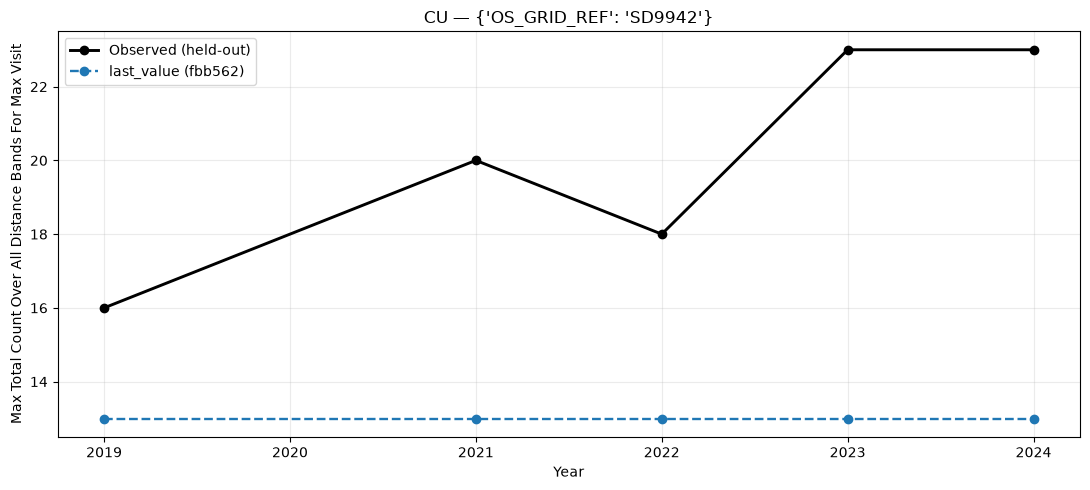

In [4]:
series_cols = [col for col in group_cols if col != "species"]
if SERIES_FILTER is None:
    if series_cols:
        combined = pd.concat([f[series_cols] for f in frames.values()], ignore_index=True)
        counts = combined.groupby(series_cols).size().sort_values(ascending=False)
        if counts.empty:
            raise ValueError("No forecast series found")
        chosen = counts.index[0]
        chosen = (chosen,) if len(series_cols) == 1 else chosen
        chosen_filter = dict(zip(series_cols, chosen))
    else:
        chosen_filter = {}
else:
    chosen_filter = dict(SERIES_FILTER)
    if set(chosen_filter) != set(series_cols):
        raise ValueError(f"SERIES_FILTER must specify exactly these grouping keys: {series_cols}")
    chosen_filter = {name: str(value) for name, value in chosen_filter.items()}

def select_series(frame):
    result = frame
    for col, val in chosen_filter.items():
        result = result.loc[result[col].astype(str).eq(str(val))]
    return result.sort_values(time_col)

plot_actual = select_series(actuals)
plot_predictions = {name: select_series(frame) for name, frame in frames.items()}
if all(frame.empty for frame in plot_predictions.values()):
    raise ValueError(f"No predictions for {chosen_filter}; choose another series")

fig, ax = plt.subplots(figsize=(11, 5))
if not plot_actual.empty:
    ax.plot(plot_actual[time_col], plot_actual[target_col], "o-",
            color="black", lw=2.1, label="Observed (held-out)")
for name, frame in plot_predictions.items():
    if not frame.empty:
        ax.plot(frame[time_col], frame["prediction"], "o--",
                lw=1.7, label=labels[name])
ax.set(title=f"{species} — {chosen_filter or 'aggregate series'}",
       xlabel=time_col.title(), ylabel=target_col.replace("_", " ").title())
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Compare models on the same evaluated observations

For a fair comparison, this section keeps only keys for which **every selected
model** made a prediction **and** the actual count is observed. That means
identical square–year rows contribute to each model's metric and annual mean.
If you use a different split or dataset version, the overlap may be smaller.

The species-level plot is the **mean recorded count over the common evaluated
squares**, *not* a population abundance index. Numbers of surveyed squares
can differ between years, so interpret changes with care.

,model,n_scored,MAE,RMSE,bias (actual - predicted)
0,last_value (fbb562),2397,3.07,6.174,-0.22


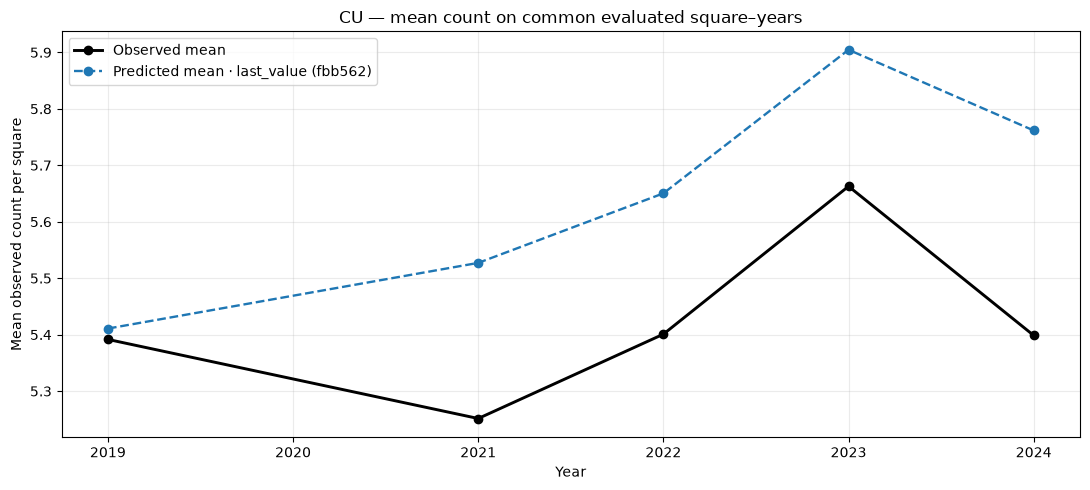

,year,n_scored,observed_mean,pred_0
0,2019,572,5.392,5.411
1,2021,497,5.252,5.527
2,2022,449,5.401,5.650
3,2023,430,5.663,5.905
4,2024,449,5.399,5.762


In [5]:
common = actuals[[*keys, target_col]].copy()
for i, (name, frame) in enumerate(frames.items()):
    # Only score rows that this experiment itself marks as observed.
    scored = frame.loc[frame[target_col].notna(), [*keys, "prediction"]]
    common = common.merge(
        scored.rename(columns={"prediction": f"pred_{i}"}),
        on=keys, how="inner", validate="one_to_one",
    )

if common.empty:
    print("No common observed forecast rows for these runs; try fewer models or matching splits.")
else:
    metrics = []
    for i, name in enumerate(frames):
        error = common[target_col].to_numpy() - common[f"pred_{i}"].to_numpy()
        metrics.append({
            "model": labels[name], "n_scored": len(common),
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.square(error).mean()),
            "bias (actual - predicted)": error.mean(),
        })
    display(pd.DataFrame(metrics).round(3))

    summary = common.groupby(time_col).agg(
        observed_mean=(target_col, "mean"), n_scored=(target_col, "size"),
        **{f"pred_{i}": (f"pred_{i}", "mean") for i in range(len(frames))},
    ).reset_index().sort_values(time_col)
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(summary[time_col], summary["observed_mean"], "o-",
            color="black", lw=2.1, label="Observed mean")
    for i, name in enumerate(frames):
        ax.plot(summary[time_col], summary[f"pred_{i}"], "o--",
                lw=1.7, label=f"Predicted mean · {labels[name]}")
    ax.set(title=f"{species} — mean count on common evaluated square–years",
           xlabel=time_col.title(), ylabel="Mean observed count per square")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(summary[[time_col, "n_scored", "observed_mean",
                     *[f"pred_{i}" for i in range(len(frames))]]].round(3))

### Interpreting these plots

- A zero **is plotted** when the count is explicitly observed as zero.
- Missing actual counts **are not scored** and never changed to zero.
- Saved CSVs from `save_forecast_results()` generally contain **test-period
  predictions only**. The first plot does not pretend predictions exist for the
  training years.
- For model comparisons, choose folders with matching evaluation windows,
  target definitions, and data releases; the code compares only overlapping
  scored keys, but it cannot prove the experiments are otherwise equivalent.

## 6. Map forecast error across survey squares

The maps show error **at each UKBBS square** for the selected species. They use the
**same observed square–year rows** across all selected models (from section 5).
Missing actual counts are never scored, and a square's plotted value summarises
its evaluated years (not its entire historical record).

- **Mean signed error = observed − predicted**: red means the model tends to
  **underpredict**; blue means it tends to **overpredict**. Positive and negative
  errors can cancel over time.
- **MAE = mean absolute error**: the size of the typical error, regardless of sign.
- `SPATIAL_YEAR = None` shows each square's average over all shared test years.
  Set a year (e.g. `2022`) to map errors for that year alone.

Coordinates come from `data/processed/locations.csv` (fallback:
`ukbbs_model_data_with_coordinates.csv`) generated by preprocessing notebook 01.
They are **EPSG:3035 projected coordinates**, *not longitude/latitude*. The
plots show survey-square points without a coastline or basemap. Colour limits
are shared between models for each error metric, but squares with only one
scored year will have less stable estimates than squares with many years.


In [6]:
# Optional: view a single test year instead of a mean over all shared years.
SPATIAL_YEAR = None  # e.g. 2022

if "OS_GRID_REF" not in group_cols:
    raise ValueError("Spatial maps require OS_GRID_REF in the forecast task's group columns")

if common.empty:
    print("No shared observed predictions to map. Select runs with overlapping scored rows.")
else:
    spatial_rows = common.copy()
    if SPATIAL_YEAR is not None:
        spatial_rows = spatial_rows.loc[
            spatial_rows[time_col].eq(int(SPATIAL_YEAR))
        ].copy()

    if spatial_rows.empty:
        print(f"No common scored predictions for year {SPATIAL_YEAR!r}.")
    else:
        coord_paths = [
            PROJECT_ROOT / "data" / "processed" / "locations.csv",
            PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data_with_coordinates.csv",
        ]
        coord_path = next((p for p in coord_paths if p.is_file()), None)
        if coord_path is None:
            raise FileNotFoundError(
                "Spatial maps require data/processed/locations.csv or "
                "ukbbs_model_data_with_coordinates.csv. Run preprocessing notebook 01."
            )

        coords = pd.read_csv(
            coord_path,
            usecols=["OS_GRID_REF", "easting", "northing", "coordinate_crs"],
            dtype={"OS_GRID_REF": "string", "coordinate_crs": "string"},
        )
        crs_values = set(coords["coordinate_crs"].dropna().unique())
        if crs_values != {"EPSG:3035"}:
            raise ValueError(f"Expected EPSG:3035 coordinates in {coord_path}: {crs_values}")
        for col in ("easting", "northing"):
            coords[col] = pd.to_numeric(coords[col], errors="coerce")
        coords = coords.drop(columns="coordinate_crs")
        # The fallback observation table repeats coordinates across species/years.
        conflicts = coords.groupby("OS_GRID_REF")[["easting", "northing"]].nunique(dropna=False)
        if conflicts.gt(1).any(axis=1).any():
            raise ValueError(f"Conflicting coordinates for squares in {coord_path}")
        coords = coords.drop_duplicates("OS_GRID_REF")

        spatial_rows = spatial_rows.merge(
            coords, on="OS_GRID_REF", how="left", validate="many_to_one"
        )
        has_coordinates = (
            spatial_rows[["easting", "northing"]].notna().all(axis=1)
            & np.isfinite(spatial_rows[["easting", "northing"]]).all(axis=1)
        )
        if not has_coordinates.all():
            print(
                f"Warning: omitting {(~has_coordinates).sum():,} scored rows at "
                f"{spatial_rows.loc[~has_coordinates, 'OS_GRID_REF'].nunique():,} "
                "squares without valid coordinates (same rows omitted for all models)."
            )
            spatial_rows = spatial_rows.loc[has_coordinates].copy()
        if spatial_rows.empty:
            raise ValueError("No scored prediction rows have usable coordinates")

        print(
            f"Spatial maps: {species}; {len(spatial_rows):,} common scored rows; "
            f"{spatial_rows.OS_GRID_REF.nunique():,} squares; "
            f"year: {SPATIAL_YEAR if SPATIAL_YEAR is not None else 'all evaluated years'}"
        )


Spatial maps: CU; 2,397 common scored rows; 907 squares; year: all evaluated years


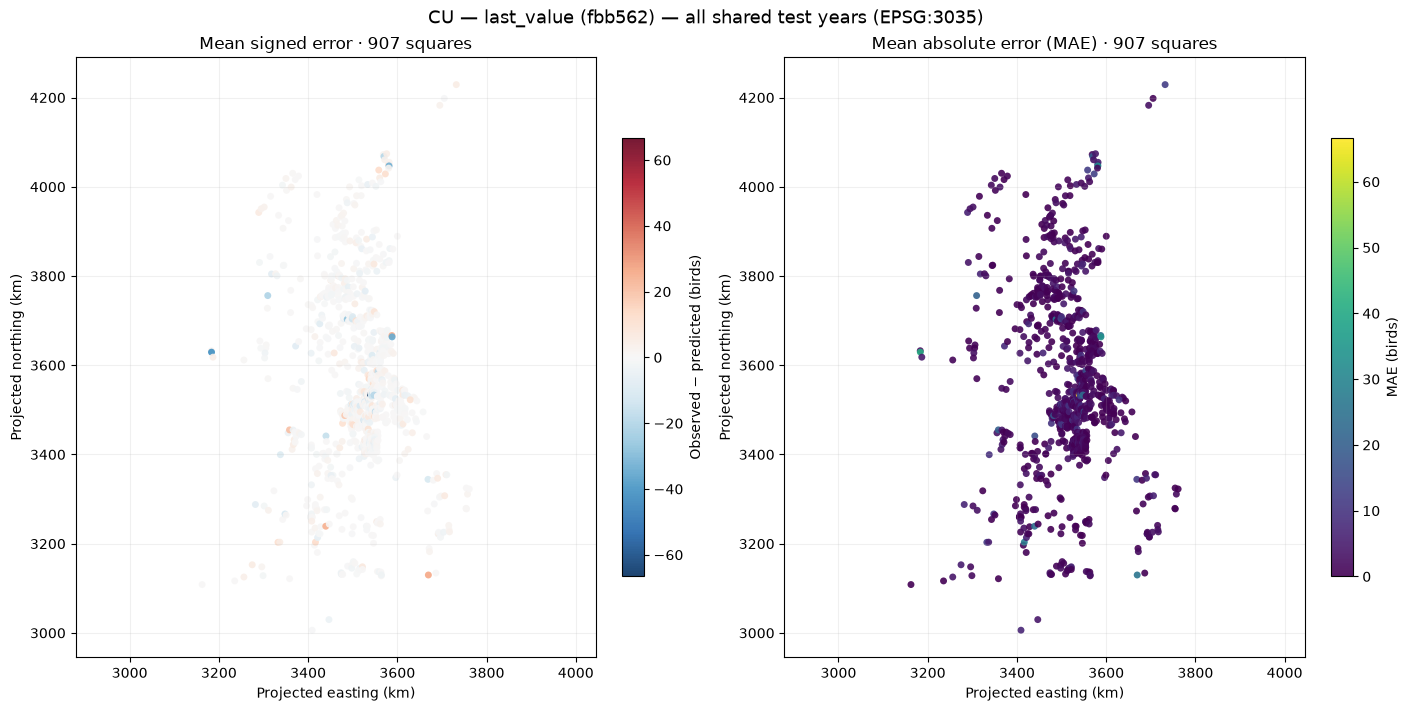

Largest spatial errors: last_value (fbb562) (interpret with n_scored)


,OS_GRID_REF,n_scored,mean_signed_error,mae
542,SD9592,5,-66.60,66.60
14,IH1561,1,-41.00,41.00
295,NU2127,2,-33.50,33.50
9,HY4803,2,-32.00,32.00
827,ST2846,4,12.25,27.25
226,NT1549,1,-27.00,27.00
903,TQ9015,1,26.00,26.00
833,ST4585,2,24.00,24.00
293,NU2030,1,24.00,24.00
572,SE0392,5,-19.00,23.40


In [ ]:
if not common.empty and not spatial_rows.empty:
    # Compute per-square summaries, independently for each model but on identical rows.
    by_model = {}
    for i, name in enumerate(frames):
        errors = spatial_rows[["OS_GRID_REF", "easting", "northing"]].copy()
        errors["signed_error"] = spatial_rows[target_col] - spatial_rows[f"pred_{i}"]
        by_model[name] = errors.groupby("OS_GRID_REF", as_index=False).agg(
            easting=("easting", "first"),
            northing=("northing", "first"),
            n_scored=("signed_error", "size"),
            mean_signed_error=("signed_error", "mean"),
            mae=("signed_error", lambda s: s.abs().mean()),
        )

    # Consistent colour scales make maps across different models comparable.
    signed_max = max(
        1e-9, *(float(x["mean_signed_error"].abs().max()) for x in by_model.values())
    )
    mae_max = max(1e-9, *(float(x["mae"].max()) for x in by_model.values()))

    for name, squares in by_model.items():
        fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
        for ax, metric, title, cmap, vmin, vmax, legend in [
            (axes[0], "mean_signed_error", "Mean signed error", "RdBu_r",
             -signed_max, signed_max, "Observed − predicted (birds)"),
            (axes[1], "mae", "Mean absolute error (MAE)", "viridis",
             0, mae_max, "MAE (birds)"),
        ]:
            points = ax.scatter(
                squares["easting"] / 1000, squares["northing"] / 1000,
                c=squares[metric], cmap=cmap, vmin=vmin, vmax=vmax,
                s=25, alpha=0.9, linewidths=0,
            )
            ax.set_title(f"{title} · {len(squares):,} squares")
            ax.set_xlabel("Projected easting (km)")
            ax.set_ylabel("Projected northing (km)")
            ax.set_aspect("equal", adjustable="datalim")
            ax.grid(alpha=0.18)
            fig.colorbar(points, ax=ax, label=legend, shrink=0.73)

        span = SPATIAL_YEAR if SPATIAL_YEAR is not None else "all shared test years"
        fig.suptitle(f"{species} — {labels[name]} — {span} (EPSG:3035)", fontsize=13)
        plt.show()
        print(f"Largest spatial errors: {labels[name]} (interpret with n_scored)")
        display(squares.sort_values("mae", ascending=False)[[
            "OS_GRID_REF", "n_scored", "mean_signed_error", "mae"
        ]].head(100).round(2))
